In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_DIR = Path(
    "/Users/kakulrajput/Documents/Image_Detection"
)

DATASET_DIR = (
    PROJECT_DIR / "data" / "processed" / "image_dataset"
)

print("Dataset exists:", DATASET_DIR.exists())
print("Dataset path:", DATASET_DIR)

Dataset exists: True
Dataset path: /Users/kakulrajput/Documents/Image_Detection/data/processed/image_dataset


In [2]:
splits = ["train", "val", "test"]
classes = ["safe", "unsafe"]

counts = {}

for split in splits:
    counts[split] = {}

    for label in classes:
        folder = DATASET_DIR / split / label

        counts[split][label] = sum(
            1 for file in folder.iterdir()
            if file.is_file()
        )

counts_df = pd.DataFrame(counts).T

counts_df.index.name = "Dataset Split"

display(counts_df)

,safe,unsafe
Dataset Split,,
train,1709,1900
val,369,402
test,364,409


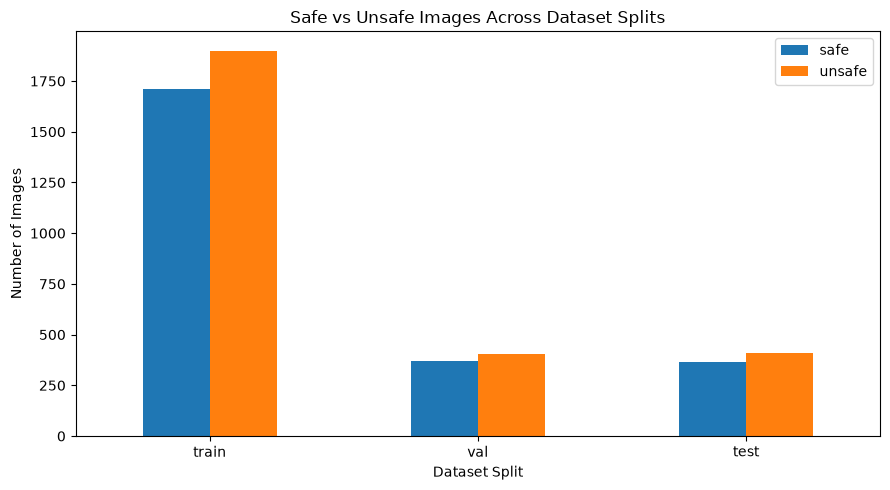

In [3]:
counts_df.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Safe vs Unsafe Images Across Dataset Splits")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

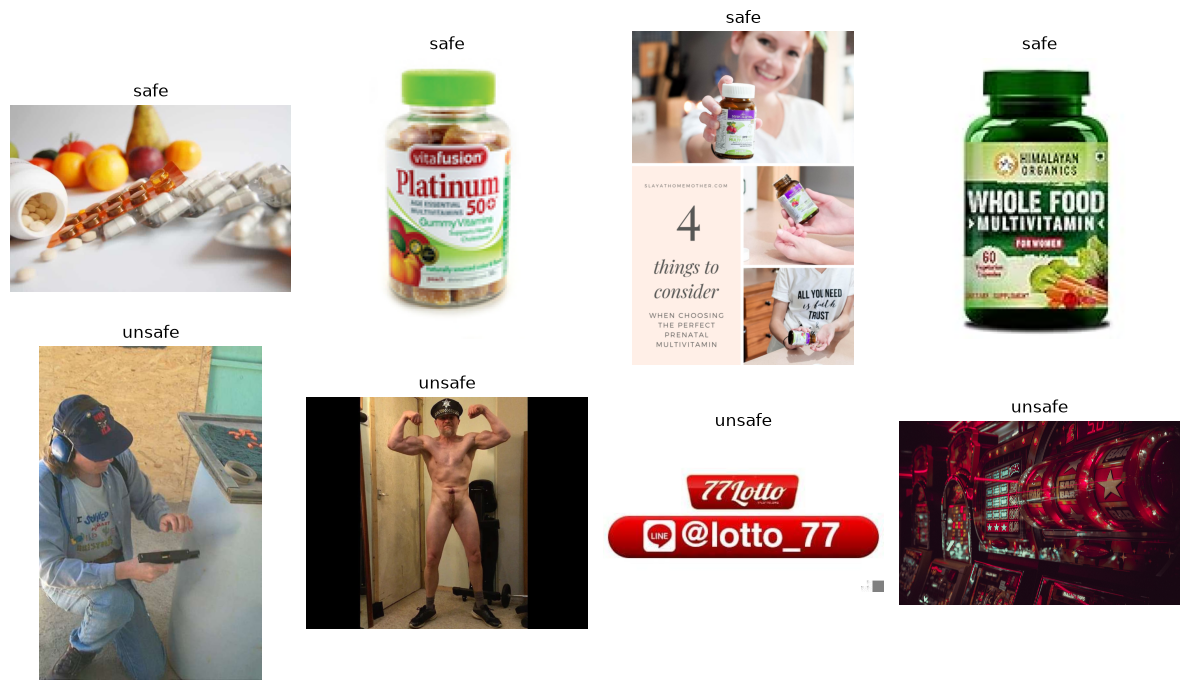

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(12, 7))

for row, label in enumerate(classes):
    image_folder = DATASET_DIR / "train" / label

    image_paths = sorted(image_folder.glob("*"))[:4]

    for col, image_path in enumerate(image_paths):
        with Image.open(image_path) as image:
            axes[row, col].imshow(image.convert("RGB"))

        axes[row, col].set_title(label)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [5]:
dimension_records = []

for split in splits:
    for label in classes:
        folder = DATASET_DIR / split / label

        for image_path in folder.iterdir():
            if not image_path.is_file():
                continue

            try:
                with Image.open(image_path) as image:
                    width, height = image.size

                dimension_records.append({
                    "split": split,
                    "label": label,
                    "width": width,
                    "height": height,
                })

            except Exception as error:
                print(f"Could not inspect {image_path}: {error}")

dimensions_df = pd.DataFrame(dimension_records)

display(dimensions_df.head())

print("Images inspected:", len(dimensions_df))
print("\nWidth statistics:")
display(dimensions_df["width"].describe())

print("\nHeight statistics:")
display(dimensions_df["height"].describe())

,split,label,width,height
0,train,safe,640,640
1,train,safe,300,450
2,train,safe,300,168
3,train,safe,227,340
4,train,safe,480,320


Images inspected: 5153

Width statistics:


count     5153.000000
mean       880.540268
std       1299.332349
min         48.000000
25%        271.000000
50%        427.000000
75%        640.000000
max      10507.000000
Name: width, dtype: float64


Height statistics:


count    5153.000000
mean      823.106540
std      1220.339987
min        44.000000
25%       314.000000
50%       416.000000
75%       640.000000
max      9071.000000
Name: height, dtype: float64